# NLP-3: Data exploration and class-prior baseline

Run in order after placing the competition `train.csv` in `data/raw/`. Outputs are initially empty: no dataset findings are claimed. Labels: 0 = A wins, 1 = B wins, 2 = tie. This is separate from the breast-cancer/digits lab.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src/baseline.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src/baseline.py").exists():
    raise RuntimeError("Open this notebook from the project root or notebooks folder.")
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from src.baseline import load_data, saved_split, main
FIGURES = ROOT / "results/figures"
FIGURES.mkdir(parents=True, exist_ok=True)

Matplotlib is building the font cache; this may take a moment.


## 1. Load and validate
The loader checks required columns, unique IDs, one-hot labels, and multi-turn JSON structure. Model names and IDs are not predictive features.

In [2]:
df, fingerprint = load_data()
print("Rows:", len(df))
print("Columns:", df.columns.tolist())
print("Dataset SHA256:", fingerprint)
print("Missing values:")
print(df.isna().sum())
print("Repeated prompt rows:", df.prompt_group.duplicated().sum())
print("Duplicate prompt/response triplets:", df.duplicated(["prompt_text", "response_a_text", "response_b_text"]).sum())

Rows: 57477
Columns: ['id', 'model_a', 'model_b', 'prompt', 'response_a', 'response_b', 'winner_model_a', 'winner_model_b', 'winner_tie', 'label', 'prompt_text', 'prompt_group', 'response_a_text', 'response_b_text']
Dataset SHA256: 0692154aaf20fc6649090c3f49b6b5dd1e693a765ecb5f0856ae0da5946f5be2
Missing values:
id                 0
model_a            0
model_b            0
prompt             0
response_a         0
response_b         0
winner_model_a     0
winner_model_b     0
winner_tie         0
label              0
prompt_text        0
prompt_group       0
response_a_text    0
response_b_text    0
dtype: int64
Repeated prompt rows: 5743
Duplicate prompt/response triplets: 71


## 2. Class balance and text lengths
Review these outputs and write what you observe. Class imbalance can make majority-class accuracy misleading.

       count  percentage
label                   
0      20064   34.907876
1      19652   34.191068
2      17761   30.901056


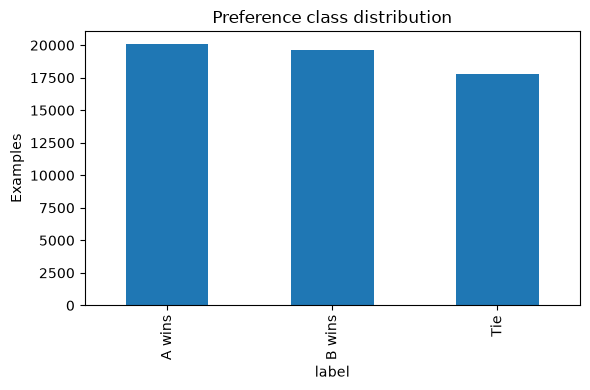

In [3]:
counts = df.label.value_counts().reindex([0, 1, 2], fill_value=0)
print(pd.DataFrame({"count": counts, "percentage": counts / len(df) * 100}))
fig, ax = plt.subplots(figsize=(6, 4))
counts.rename(index={0:"A wins", 1:"B wins", 2:"Tie"}).plot.bar(ax=ax)
ax.set_ylabel("Examples")
ax.set_title("Preference class distribution")
fig.tight_layout()
fig.savefig(FIGURES / "class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

         prompt  response_a  response_b
count  57477.00    57477.00    57477.00
mean     352.36     1330.37     1337.18
std     1025.38     1461.91     1483.79
min        3.00        0.00        0.00
25%       48.00      391.00      395.00
50%       91.00     1036.00     1044.00
75%      233.00     1810.00     1819.00
max    32833.00    53299.00    52402.00


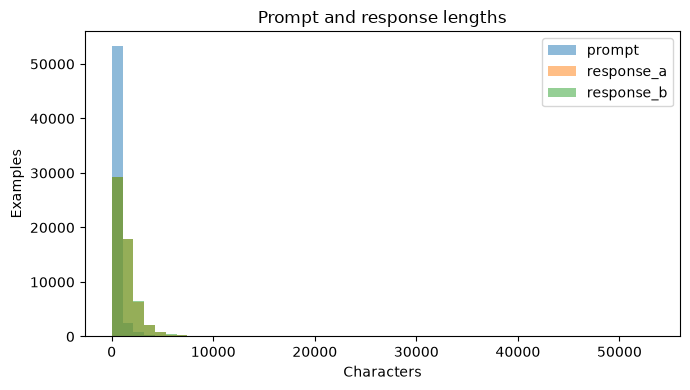

In [4]:
lengths = pd.DataFrame({col: df[col + "_text"].str.len() for col in ["prompt", "response_a", "response_b"]})
print(lengths.describe().round(2))
fig, ax = plt.subplots(figsize=(7, 4))
lengths.plot.hist(bins=50, alpha=0.5, ax=ax)
ax.set_xlabel("Characters")
ax.set_ylabel("Examples")
ax.set_title("Prompt and response lengths")
fig.tight_layout()
fig.savefig(FIGURES / "text_lengths.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

## 3. Save reusable prompt-grouped splits
Approximately 60% training, 20% validation, 20% final local test. Grouping takes precedence over exact ratios. Existing split files are reused and checked against the dataset fingerprint. Share IDs privately with teammates; inspect additional source/duplicate-response leakage before claiming a complete audit.

In [5]:
split = saved_split(df, fingerprint)
print(pd.crosstab(split, df.label))
print("Saved assignments:", ROOT / "data/splits/split_ids.csv")

label           0      1      2
row_0                          
test         4012   3930   3552
train       12039  11791  10657
validation   4013   3931   3552
Saved assignments: /Users/t.sumithreddy/iCloud Drive (Archive)/Documents/comp-6721-project/data/splits/split_ids.csv


## 4. Class-prior validation baseline
This uses training class proportions only and evaluates on validation. The final local test is not scored. It also records package versions.

In [6]:
main()

Dataset shape: (57477, 14)
Class counts (0=A, 1=B, 2=tie):
 label
0    20064
1    19652
2    17761
Name: count, dtype: int64
Missing values:
 id                 0
model_a            0
model_b            0
prompt             0
response_a         0
response_b         0
winner_model_a     0
winner_model_b     0
winner_tie         0
label              0
prompt_text        0
prompt_group       0
response_a_text    0
response_b_text    0
dtype: int64
Repeated prompt rows: 5743
Partition counts:
 label           0      1      2
id                             
test         4012   3930   3552
train       12039  11791  10657
validation   4013   3931   3552
{
  "model": "training_class_prior",
  "evaluation_partition": "validation",
  "dataset_sha256": "0692154aaf20fc6649090c3f49b6b5dd1e693a765ecb5f0856ae0da5946f5be2",
  "seed": 42,
  "class_order": [
    "A wins",
    "B wins",
    "tie"
  ],
  "training_priors": [
    0.3490880621683533,
    0.3418969466755589,
    0.3090149911560878
  ],
  "lo

## 5. Write the first findings

Replace the pending entries in `reports/first_draft_report.md` with actual observations:
- What are the class counts and majority fraction?
- Are any fields missing or examples duplicated?
- Can prompts or other sources leak across partitions?
- What are the validation log loss, accuracy, and macro F1?
- What does the baseline fail to capture?

Next: numerical-feature and TF-IDF logistic-regression baselines on exactly these split IDs. Keep calibration fitting separate from final local test evaluation.